In [ ]:
"""
BCSE331P - Assessment 9: Principal Component Analysis (Python)
NAME: P BALAJI SUBRAMANIAN
REG NO: 23BDS0271
"""

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

CSV_PATH = "orange_juice_withmissing.csv"
REG_NO = "0271"   # <-- put your registration number here

In [ ]:
# 1. Load dataset 
df = pd.read_csv(CSV_PATH)

In [3]:
# 2. Rows and columns
print(f"2. Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

2. Rows: 1070, Columns: 18



In [4]:
# 3. Numeric columns, clean, scale -> data_scaled
num = df.select_dtypes(include=np.number).copy()
num = num.fillna(num.median())
num = num.loc[:, num.std() > 0]                     # drop constant columns
data_scaled = pd.DataFrame(StandardScaler().fit_transform(num), columns=num.columns)
print("3. data_scaled shape:", data_scaled.shape, "\n")

3. data_scaled shape: (1070, 16) 



In [5]:
# 4. PCA + summary 
pca = PCA()
scores = pca.fit_transform(data_scaled)
n_pc = scores.shape[1]
pc_names = [f"PC{i+1}" for i in range(n_pc)]
summary = pd.DataFrame({
    "Std Dev": np.sqrt(pca.explained_variance_),
    "Prop. Variance": pca.explained_variance_ratio_,
    "Cumulative": np.cumsum(pca.explained_variance_ratio_),
}, index=pc_names).round(4)
print("4. PCA summary:\n", summary, "\n")

4. PCA summary:
       Std Dev  Prop. Variance  Cumulative
PC1    2.0509          0.2626      0.2626
PC2    1.9113          0.2281      0.4907
PC3    1.6744          0.1751      0.6658
PC4    1.2672          0.1003      0.7661
PC5    1.0633          0.0706      0.8367
PC6    0.9210          0.0530      0.8896
PC7    0.8747          0.0478      0.9374
PC8    0.6745          0.0284      0.9658
PC9    0.6325          0.0250      0.9908
PC10   0.3670          0.0084      0.9992
PC11   0.0781          0.0004      0.9996
PC12   0.0579          0.0002      0.9998
PC13   0.0385          0.0001      0.9999
PC14   0.0352          0.0001      1.0000
PC15   0.0230          0.0000      1.0000
PC16   0.0000          0.0000      1.0000 



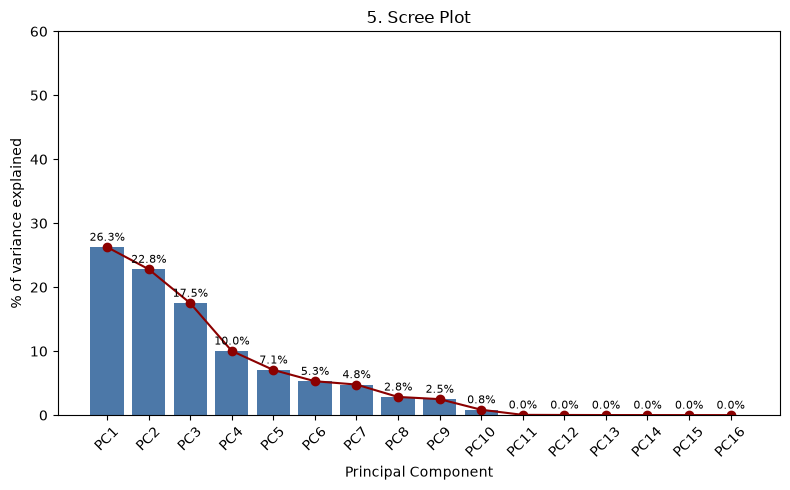

In [6]:
# 5. Scree plot with data labels, y-axis 0-60
var_pct = pca.explained_variance_ratio_ * 100
plt.figure(figsize=(8, 5))
plt.bar(pc_names, var_pct, color="#4c78a8")
plt.plot(pc_names, var_pct, "o-", color="darkred")
for i, v in enumerate(var_pct):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=8)
plt.ylim(0, 60)
plt.title("5. Scree Plot"); plt.xlabel("Principal Component"); plt.ylabel("% of variance explained")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

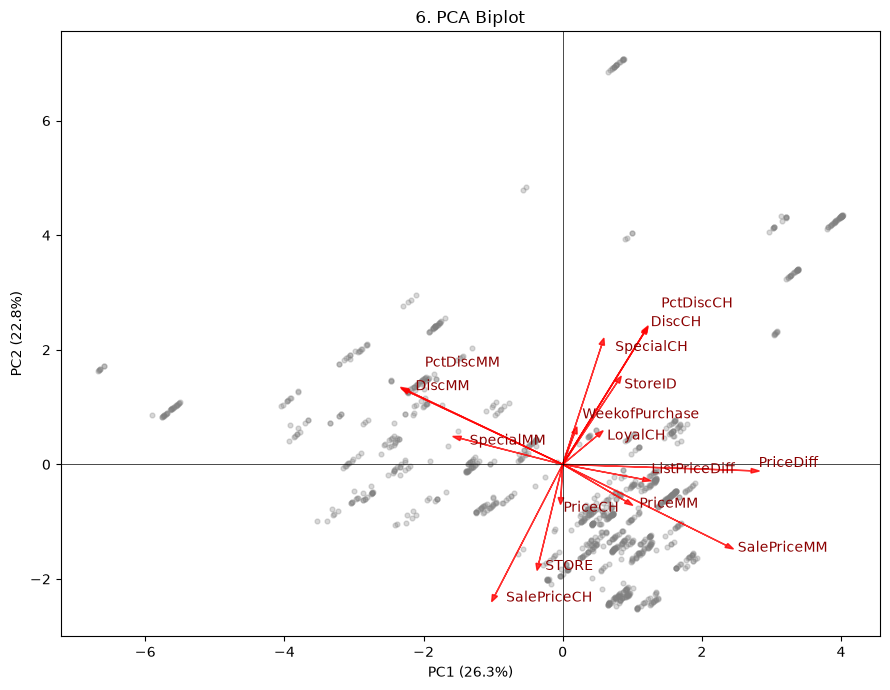

In [7]:
# 6. Biplot with non-overlapping labels
from adjustText import adjust_text
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(scores[:, 0], scores[:, 1], s=12, alpha=0.3, color="grey")
loadings = pca.components_[:2].T
scale = np.abs(scores[:, :2]).max() * 0.8
texts = []
for i, name in enumerate(data_scaled.columns):
    ax.arrow(0, 0, loadings[i, 0] * scale, loadings[i, 1] * scale,
             color="red", head_width=0.08, alpha=0.8)
    texts.append(ax.text(loadings[i, 0] * scale, loadings[i, 1] * scale, name, color="darkred"))
adjust_text(texts, ax=ax)
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}%)"); ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}%)")
ax.set_title("6. PCA Biplot")
plt.tight_layout(); plt.show()

In [8]:
# 7. PCA scores dataframe
pca_scores = pd.DataFrame(scores, columns=pc_names)
print("7. pca_scores (first six rows):\n", pca_scores.head(6), "\n")

7. pca_scores (first six rows):
         PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0  0.363980 -0.781172 -2.134124  0.218180 -0.550043  0.268918  0.424269   
1 -2.463427  0.447339 -1.435424  0.922092 -1.442740  1.514809 -0.025257   
2  1.648389  0.370846 -0.590257 -0.670592 -0.938204  0.831757  0.393734   
3 -1.340479  0.031431 -4.312523 -1.714466  0.285110  0.198832 -0.190993   
4 -0.776378  1.071861 -3.973083 -0.689068  2.653910  0.900062 -1.016071   
5  0.477109  0.600340 -2.329453  2.073619  0.183770  2.111124 -1.260429   

        PC8       PC9      PC10      PC11      PC12      PC13      PC14  \
0  0.784024  0.063925 -0.494875 -0.014745  0.017118  0.007642 -0.012158   
1 -0.299527  0.340176 -0.369089  0.025233 -0.041443  0.002240 -0.009452   
2  0.733622 -0.452782 -1.114006 -0.011309  0.017531 -0.008148  0.017542   
3  1.004594  0.251844 -0.358873 -0.037568  0.037864  0.003569 -0.006914   
4  0.154000 -0.286008  0.065763 -0.035162  0.052550 -0.002999  0.0

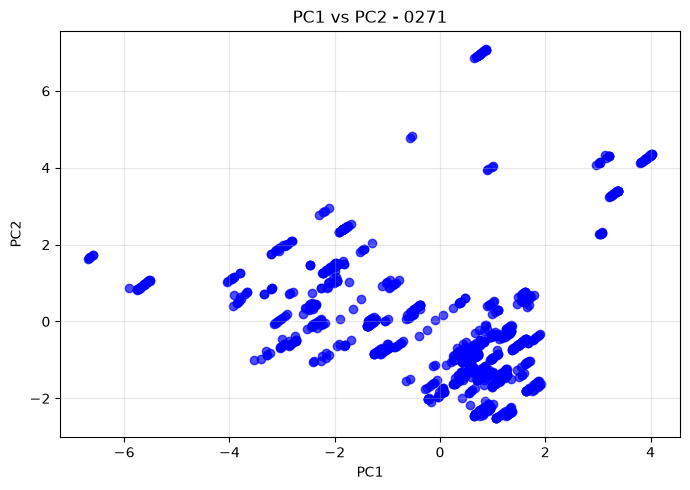

In [9]:
# 8. PC1 vs PC2 scatter, blue circles, registration number in title
plt.figure(figsize=(7, 5))
plt.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", alpha=0.7)
plt.title(f"PC1 vs PC2 - {REG_NO}")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()